&nbsp;

# HN-score Calculation Notebook

- strandness と判定したデータセットのみで HN-score の算出を行う
- related notebook: [../00_metadata/00_8_salmon_metadata_parse.ipynb](../00_metadata/00_8_salmon_metadata_parse.ipynb)

In [1]:
import os
import datetime
import pathlib
import polars as pl
import matplotlib.pyplot as plt
from matplotlib import rcParams
import pandas as pd
import numpy as np

from IPython.display import display


plt.style.use("ggplot")

In [2]:
VERSION = datetime.datetime.now().strftime("%y%m")
execute_date = datetime.datetime.now().strftime("%y%m%d")
print(f"Execute Date: {execute_date}")

# create directory
pathlib.Path(f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_{VERSION}").mkdir(parents=True, exist_ok=True)

Execute Date: 261001


&nbsp;

&nbsp;

&nbsp;

In [3]:
# transcript
HNratio = pl.read_csv(
    f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_2610/HNratio_gencode_261001_all_stranded.tsv", 
    separator="\t",
    n_threads=16
)

display(HNratio)

transcript_id,SRR27681984,SRR27681983,SRR7359799,SRR7359798,SRR7359797,SRR7359787,SRR7359786,SRR7359785,SRR7359775,SRR7359774,SRR7359773,SRR7359763,SRR7359762,SRR7359761,SRR7359751,SRR7359750,SRR7359749,SRR7359739,SRR7359738,SRR7359737,SRR7359727,SRR7359726,SRR7359725,SRR7359715,SRR7359714,SRR7359713,SRR7359703,SRR7359702,SRR7359701,SRR7359691,SRR7359690,SRR7359689,SRR7359679,SRR7359678,SRR7359677,SRR7359667,…,SRR12926169,SRR12926170,SRR12926171,SRR12926172,SRR12926177,SRR12926178,SRR12926179,SRR12926180,SRR12926185,SRR12926186,SRR12926187,SRR12926188,DRR321028,DRR321029,DRR361197,DRR361206,DRR361198,DRR361199,DRR361204,DRR361205,DRR361207,DRR361208,DRR093588,DRR093591,DRR093594,DRR093589,DRR093590,DRR093592,DRR093593,DRR093595,DRR093596,ERR5882000,ERR5881999,ERR5882001,ERR5881998,DRR214953,DRR214954
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""ENST00000832824.1""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
"""ENST00000832825.1""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
"""ENST00000832826.1""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.712111,0.414068,1.0,1.0,1.0,1.0,1.0,4.947522,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.755543,…,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.719938,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
"""ENST00000832827.1""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.386991,1.0,1.0,1.0,1.0
"""ENST00000832828.1""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ENST00000797950.1""",13.724599,0.078243,1.031404,1.231101,0.886962,1.286569,0.009513,0.970588,1.519393,92.008132,81.116333,1.199224,1.153978,1.165878,1.065487,1.245504,0.955193,0.937251,1.260791,0.972436,105.790025,115.241578,1.903013,1.040781,1.061305,1.018918,97.240505,1.43991,1.288855,1.489366,0.01336,96.577181,1.173286,1.433092,1.3549,1.517125,…,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.32615,0.45877,2.667843,0.60771,0.024561,0.026198,0.979479,3.418718,1.524544,0.403213,0.074046,2.22939,1.096211,0.365808,1.597985,0.685427,2.129594,0.638244,0.726556,1.416661,1.035847,2.583998,1.0,1.0
"""ENST00000819228.1""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,2.351505,0.923046,0.622964,1.0,1.0,1.0,1.0,1.0,4.213419,0.251893,0.665485,1.050639,4.029291,1.0,3.62148,1.0,0.203484,1.0,2.525538,1.209984,0.776027,4.044449,1.0,4.67847,4.442579,4.026815,1.0,1.262411,…,1.0,0.265253,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.12088,1.133129,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,4.251749,3.29071,1.0,1.0,6.210704,6.120833,7.363173,12.467048,1.0,1.0,1.0,1.0,1.0,1.0
"""ENST00000819229.1""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1

&nbsp;

&nbsp;

&nbsp;

## Assign the flag (`UP` , `DOWN`, `UNCHANGED`)

In [4]:
# set the threshold
threshold = 2

# define a function to categorize the HNratio
def categorize(x):
    if x >= threshold:
        return 'UP'
    elif x <= 1/threshold:
        return 'DOWN'
    else:
        return 'UNCHANGED'



# apply the categorize function to all columns except GENEID
result = HNratio.with_columns([
    pl.col(col).map_elements(categorize, return_dtype=pl.String).alias(f"{col}_category")
    for col in HNratio.columns if col != 'transcript_id'
])

result = result.drop(
    [col for col in result.columns if not col.endswith('_category') and col != 'transcript_id']
)

result.write_csv(
    f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_{VERSION}/HNratio_categorized_{threshold}_stranded.tsv", 
    separator="\t"
)

# display the result
display(result)

transcript_id,SRR27681984_category,SRR27681983_category,SRR7359799_category,SRR7359798_category,SRR7359797_category,SRR7359787_category,SRR7359786_category,SRR7359785_category,SRR7359775_category,SRR7359774_category,SRR7359773_category,SRR7359763_category,SRR7359762_category,SRR7359761_category,SRR7359751_category,SRR7359750_category,SRR7359749_category,SRR7359739_category,SRR7359738_category,SRR7359737_category,SRR7359727_category,SRR7359726_category,SRR7359725_category,SRR7359715_category,SRR7359714_category,SRR7359713_category,SRR7359703_category,SRR7359702_category,SRR7359701_category,SRR7359691_category,SRR7359690_category,SRR7359689_category,SRR7359679_category,SRR7359678_category,SRR7359677_category,SRR7359667_category,…,SRR12926169_category,SRR12926170_category,SRR12926171_category,SRR12926172_category,SRR12926177_category,SRR12926178_category,SRR12926179_category,SRR12926180_category,SRR12926185_category,SRR12926186_category,SRR12926187_category,SRR12926188_category,DRR321028_category,DRR321029_category,DRR361197_category,DRR361206_category,DRR361198_category,DRR361199_category,DRR361204_category,DRR361205_category,DRR361207_category,DRR361208_category,DRR093588_category,DRR093591_category,DRR093594_category,DRR093589_category,DRR093590_category,DRR093592_category,DRR093593_category,DRR093595_category,DRR093596_category,ERR5882000_category,ERR5881999_category,ERR5882001_category,ERR5881998_category,DRR214953_category,DRR214954_category
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""ENST00000832824.1""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""",…,"""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED"""
"""ENST00000832825.1""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""",…,"""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UNCHANGED""","""UN

In [5]:
# https://docs.pola.rs/api/python/stable/reference/expressions/api/polars.sum_horizontal.html#polars-sum-horizontal
count = result.with_columns([
    (pl.sum_horizontal([
        (pl.col(col) == "UP").cast(pl.Int32) for col in result.columns if col != "transcript_id"
    ])).alias(f"UP{threshold}"),
    (pl.sum_horizontal([
        (pl.col(col) == "DOWN").cast(pl.Int32) for col in result.columns if col != "transcript_id"
    ])).alias(f"DOWN{threshold}"),
    pl.sum_horizontal([
        (pl.col(col) == "UNCHANGED").cast(pl.Int32) for col in result.columns if col != "transcript_id"
    ]).alias(f"UNCHANGED{threshold}")
]).drop(
    [col for col in result.columns if col != 'transcript_id']
).with_columns([
    (pl.col(f"UP{threshold}") - pl.col(f"DOWN{threshold}")).alias(f"HN{threshold}"),
    ((pl.col(f"UP{threshold}") + 1) / (pl.col(f"DOWN{threshold}") + 1)).alias(f"UPcount+1 / DOWNcount+1 {threshold}"),
]).with_columns(
    (pl.col(f"UPcount+1 / DOWNcount+1 {threshold}").log(base=2)).alias(f"log2(UPcount+1 / DOWNcount+1) {threshold}"),
).sort(by=f"HN{threshold}", descending=True)


display(count)

transcript_id,UP2,DOWN2,UNCHANGED2,HN2,UPcount+1 / DOWNcount+1 2,log2(UPcount+1 / DOWNcount+1) 2
str,i32,i32,i32,i32,f64,f64
"""ENST00000309758.6""",232,4,15,228,46.6,5.542258
"""ENST00000679223.2""",222,1,28,221,111.5,6.8009
"""ENST00000450744.1""",223,4,24,219,44.8,5.485427
"""ENST00000540260.1""",216,1,34,215,108.5,6.761551
"""ENST00000555662.1""",215,5,31,210,36.0,5.169925
…,…,…,…,…,…,…
"""ENST00000497231.7""",10,182,59,-172,0.060109,-4.056268
"""ENST00000413097.6""",11,183,57,-172,0.065217,-3.938599
"""ENST00000299238.7""",8,181,62,-173,0.049451,-4.33787


In [6]:
count.write_csv(
    f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_{VERSION}/HNscore_gencode_human_{execute_date}_HN{threshold}_transcript_all_stranded.tsv",
    separator="\t"
)

&nbsp;

&nbsp;

&nbsp;

# Selection of Gene Groups

&nbsp;

&nbsp;

&nbsp;

## Upregulated Transcript Groups

In [7]:
# Calculate the number of genes in the top 1% and bottom 1%.
n_rows = count.height
top_1_percent_count = int(n_rows * 0.01)
bottom_1_percent_count = top_1_percent_count

# Retrieve the threshold values for the top 1% up and bottom 1% down.
hn_score_series = count.get_column(f"HN{threshold}")
top_1_percent_threshold = hn_score_series.top_k(top_1_percent_count).min()
bottom_1_percent_threshold = hn_score_series.bottom_k(bottom_1_percent_count).max()

# Retrieve the top 1% up and bottom 1% down of the data (including additional rows with the same HN-score).
top_genes = count.filter(
    pl.col(f"HN{threshold}") >= top_1_percent_threshold
)

bottom_genes = count.filter(
    pl.col(f"HN{threshold}") <= bottom_1_percent_threshold
)

# caluculate the number of genes in the top 2.5% and bottom 2.5%
top_2_5_percent_count = int(n_rows * 0.025)
bottom_2_5_percent_count = top_2_5_percent_count

# Retrieve the threshold values for the top 1% up and bottom 1% down.
hn_score_series = count.get_column(f"HN{threshold}")
top_2_5_percent_threshold = hn_score_series.top_k(top_2_5_percent_count).min()
bottom_2_5_percent_threshold = hn_score_series.bottom_k(bottom_2_5_percent_count).max()

# Retrieve the top 2.5% up and bottom 2.5% down of the data (including additional rows with the same HN-score).
top_2_5_percent_genes = count.filter(
    pl.col(f"HN{threshold}") >= top_2_5_percent_threshold
)

bottom_2_5_percent_genes = count.filter(
    pl.col(f"HN{threshold}") <= bottom_2_5_percent_threshold
)

# caluculate the number of genes in the top 5% and bottom 5%
top_5_percent_count = int(n_rows * 0.05)
bottom_5_percent_count = top_5_percent_count

# Retrieve the threshold values for the top 5% up and bottom 5% down.
hn_score_series = count.get_column(f"HN{threshold}")
top_5_percent_threshold = hn_score_series.top_k(top_5_percent_count).min()
bottom_5_percent_threshold = hn_score_series.bottom_k(bottom_5_percent_count).max()

# Retrieve the top 5% up and bottom 5% down of the data (including additional rows with the same HN-score).
top_5_percent_genes = count.filter(
    pl.col(f"HN{threshold}") >= top_5_percent_threshold
)

bottom_5_percent_genes = count.filter(
    pl.col(f"HN{threshold}") <= bottom_5_percent_threshold
)



# Print the results
print(f"Top 1% threshold (HN{threshold}): {top_1_percent_threshold}")
print(f"Bottom 1% threshold (HN{threshold}): {bottom_1_percent_threshold}")
print(f"Number of transcripts in the top 1%: {len(top_genes)}")
print(f"Number of transcripts in the bottom 1%: {len(bottom_genes)}")
print(f"Top 2.5% threshold (HN{threshold}): {top_2_5_percent_threshold}")
print(f"Bottom 2.5% threshold (HN{threshold}): {bottom_2_5_percent_threshold}")
print(f"Number of transcripts in the top 2.5%: {len(top_2_5_percent_genes)}")
print(f"Number of transcripts in the bottom 2.5%: {len(bottom_2_5_percent_genes)}")
print(f"Top 5% threshold (HN{threshold}): {top_5_percent_threshold}")
print(f"Bottom 5% threshold (HN{threshold}): {bottom_5_percent_threshold}")
print(f"Number of transcripts in the top 5%: {len(top_5_percent_genes)}")
print(f"Number of transcripts in the bottom 5%: {len(bottom_5_percent_genes)}")

Top 1% threshold (HN2): 80
Bottom 1% threshold (HN2): -68
Number of transcripts in the top 1%: 5247
Number of transcripts in the bottom 1%: 5295
Top 2.5% threshold (HN2): 51
Bottom 2.5% threshold (HN2): -49
Number of transcripts in the top 2.5%: 13167
Number of transcripts in the bottom 2.5%: 13306
Top 5% threshold (HN2): 31
Bottom 5% threshold (HN2): -35
Number of transcripts in the top 5%: 26896
Number of transcripts in the bottom 5%: 25910


In [8]:
HN_top_1_percent_transcripts = top_genes.filter(
    pl.col(f"HN{threshold}") >= top_1_percent_threshold
)

HN_top_2_5_percent_transcripts = top_2_5_percent_genes.filter(
    pl.col(f"HN{threshold}") >= top_2_5_percent_threshold
)

HN_top_5_percent_transcripts = top_5_percent_genes.filter(
    pl.col(f"HN{threshold}") >= top_5_percent_threshold
)

HN_top_1_percent_transcripts.write_csv(
    f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_{VERSION}/HN{threshold}_top_1_percent_transcripts_stranded.tsv",
    separator="\t"
)

HN_top_2_5_percent_transcripts.write_csv(
    f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_{VERSION}/HN{threshold}_top_2_5_percent_transcripts_stranded.tsv",
    separator="\t"
)

HN_top_5_percent_transcripts.write_csv(
    f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_{VERSION}/HN{threshold}_top_5_percent_transcripts_stranded.tsv",
    separator="\t"
)

# display(HN_top_1_percent_transcripts)
# display(HN_top_2_5_percent_transcripts)
# display(HN_top_5_percent_transcripts)

&nbsp;

&nbsp;

&nbsp;

## Downregulated Transcript Group

In [9]:
HN_bottom_1_percent_transcripts = bottom_genes.filter(
    pl.col(f"HN{threshold}") <= bottom_1_percent_threshold
)

HN_bottom_2_5_percent_transcripts = bottom_2_5_percent_genes.filter(
    pl.col(f"HN{threshold}") <= bottom_2_5_percent_threshold
)

HN_bottom_5_percent_transcripts = bottom_5_percent_genes.filter(
    pl.col(f"HN{threshold}") <= bottom_5_percent_threshold
)

HN_bottom_1_percent_transcripts.write_csv(
    f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_{VERSION}/HN{threshold}_bottom_1_percent_transcripts_stranded.tsv",
    separator="\t"
)

HN_bottom_2_5_percent_transcripts.write_csv(
    f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_{VERSION}/HN{threshold}_bottom_2_5_percent_transcripts_stranded.tsv",
    separator="\t"
)

HN_bottom_5_percent_transcripts.write_csv(
    f"../../Data/HNscore/HNscore_transcript/HNscore_gencode_{VERSION}/HN{threshold}_bottom_5_percent_transcripts_stranded.tsv",
    separator="\t"
)

# display(HN2_bottom_1_percent_transcripts)
# display(HN2_bottom_2_5_percent_transcripts)
# display(HN2_bottom_5_percent_transcripts)

&nbsp;

&nbsp;

&nbsp;

## Visualization

In [10]:
# Convert full count to pandas for plotting
count_pd = count.to_pandas()
x_data = count_pd.index.to_numpy()
y_data = count_pd[f"HN{threshold}"].to_numpy()

# Create boolean mask, then filter DataFrame with it
upregulated_mask = count_pd[f"HN{threshold}"] >= top_5_percent_threshold
upregulated_df = count_pd[upregulated_mask]  # Filter DataFrame using mask
upregulated_indices = upregulated_df.index.to_numpy()
y_data_up = upregulated_df[f"HN{threshold}"].to_numpy() # type: ignore

downregulated_mask = count_pd[f"HN{threshold}"] <= bottom_5_percent_threshold
downregulated_df = count_pd[downregulated_mask]  # Filter DataFrame using mask
downregulated_indices = downregulated_df.index.to_numpy()
y_data_down = downregulated_df[f"HN{threshold}"].to_numpy() # type: ignore

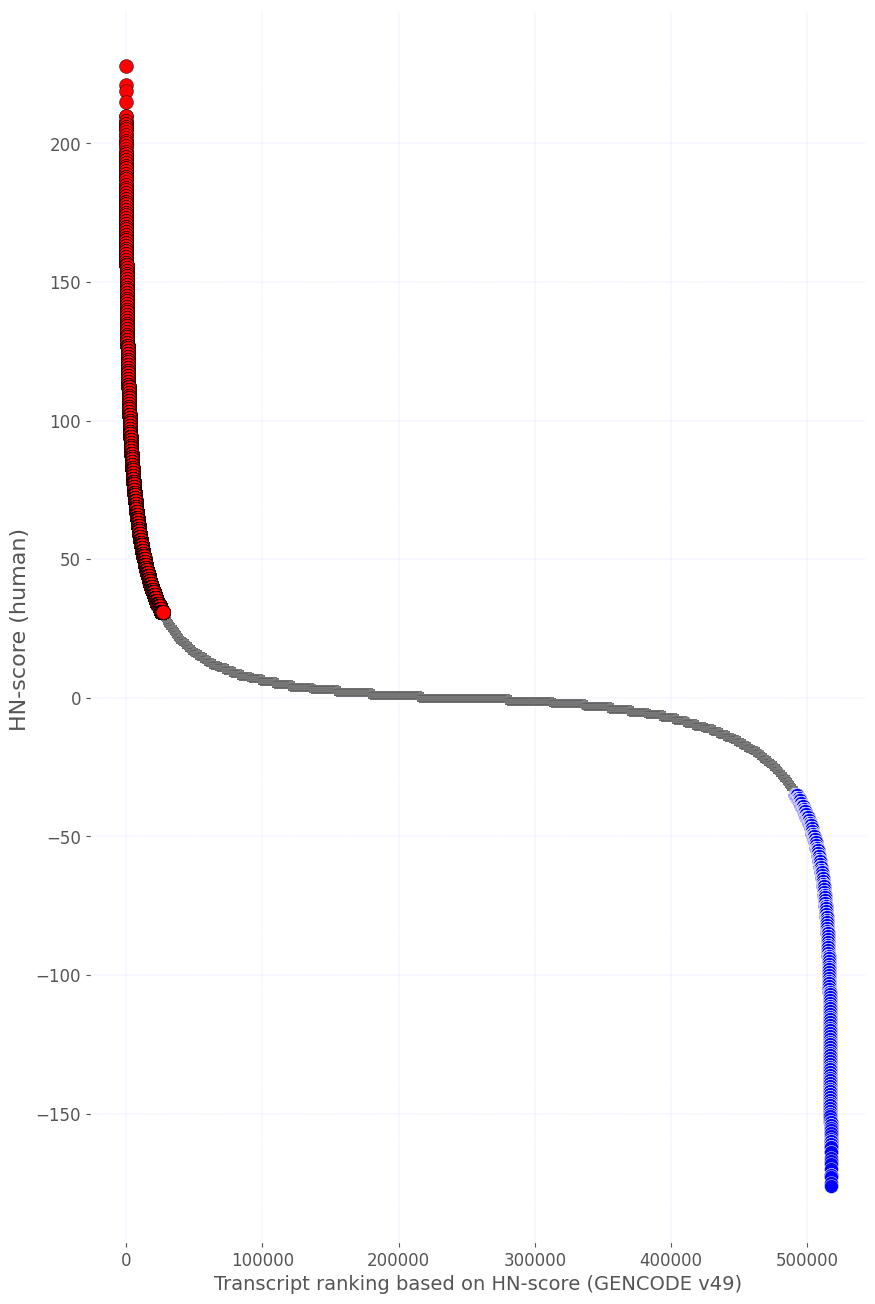

In [12]:
ax = plt.axes()
ax.set_facecolor('white')

#All genes
plt.scatter(
            x_data,
            y_data,
            s = 30,
            c="grey",
            edgecolors="black",
            linewidths=0.01,
            alpha=0.5,
            label="all genes"
            )

# upregulated genes
plt.scatter(
            upregulated_indices,
            y_data_up,
            s=100,
            c="red",
            edgecolors="black",
            linewidths=0.3,
            alpha=1,
            label="upregulated"
            )

#downregulated genes
plt.scatter(
            downregulated_indices,
            y_data_down,
            s=100,
            c="blue",
            edgecolors="white",
            linewidths=0.3,
            alpha=1,
            label="downregulated"
            )

plt.grid(color='b', linestyle=':', linewidth=0.1)
plt.rcParams["figure.figsize"] = [10, 16]  
plt.xlabel("Transcript ranking based on HN-score (GENCODE v49)", fontsize=14) 
plt.ylabel("HN-score (human) ", fontsize=16)
plt.tick_params(labelsize=12)
plt.show()